### This notebook simulates the closed-loop system with full-state feedback and uncertainties as explained in [2]. The controller is designed using the nominal matrix A as shown in the Python Notebook "FullStateFdbk_CO2case.ipynb".

### References:
[1] Nersesov, S.G., Haddad, W.M. and Chellaboina, V., 2004. Optimal fixed‐structure control for linear non‐negative dynamical systems. International Journal of Robust and Nonlinear Control: IFAC‐Affiliated Journal, 14(5), pp.487-511.

[2] Zocco, F., Haddad, W.M. and Malvezzi, M., 2025. CarboNet: A finite-time combustion-tolerant compartmental network for tropospheric carbon control. arXiv preprint arXiv:2508.16774.

[3] Python control-systems library: https://python-control.readthedocs.io/en/latest/intro.html

In [ ]:
%pip install control

import control as ct
import numpy as np

import matplotlib.pyplot as plt

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 578.3/578.3 kB 11.4 MB/s eta 0:00:00


In [ ]:
### Create the nominal matrix A:


A = np.array([[-0.2, 0.5, 0.5, 0.1, 0.5],
              [0.0, -0.7, 0.0, 0.0, 0.0],
              [0.0, 0.0, -0.4, 0.0, 0.0],
              [0.2, 0.5, 0.5, -0.1, 0.5],
              [0.0, 0.0, 0.0, 0.0, -0.2]])

B = np.array([[-1],
              [0],
              [0],
              [0],
              [0]])


C = np.identity(5)

D = np.zeros((5,1))

# Create matrix with 10% variation of entries of A:
Delta_10 = 0.1*A
A_10p = A + Delta_10
A_10m = A - Delta_10

# Create matrix with 30% variation of entries of A:
Delta_30 = 0.3*A
A_30p = A + Delta_30
A_30m = A - Delta_30

In [ ]:
# Use the nominal equilibrium point:

x1e = 637.2 #as indicated in the source paper [2], which correspond to the CO2 mass in the pre-industrial era
v_e = 0 #see source paper [2] for the reason of this condition
x2e = 0 #see source paper [2] for the reason of this condition
x3e = 0 #see source paper [2] for the reason of this condition
x7e = 0 # see source paper [2] for the reason of this condition
x4e = (0.2/0.1)*x1e
xe = np.array([[x1e],
               [x2e],
               [x3e],
               [x4e],
               [x7e]])

In [ ]:
K = [[-0.93984418, -0.66695025, -0.92842023, -0.6481119,  -1.28581432]]  #gain computed using the nominal matrix A

Now simulate the response of the closed loop to initial conditions.

In [ ]:
## Keep the inital conditions used so far:
x01 = 915.4 #as indicated in the source paper [2]
x02 = 210.0 #as indicated in the source paper [2]
x03 = 500.0 #as indicated in the source paper [2]
x04 = 1830.8 #as indicated in the source paper [2]
x07 = 4 #as indicated in the source paper [2]
x0 = np.array([[x01],
              [x02],
              [x03],
              [x04],
              [x07]])

In [ ]:
# Set the translated initial conditions (this is step (6)):
x_tilde_01 = x01 - x1e  # translated state because the control library used here expects a system of the form x_dot = Ax, whereas equation (32) of Nersesov et al. is of the form x_dot = A(x - x_e)
x_tilde_02 = x02 - x2e
x_tilde_03 = x03 - x3e
x_tilde_04 = x04 - x4e
x_tilde_07 = x07 - x7e

x_tilde_0 = np.array([[x_tilde_01],
              [x_tilde_02],
              [x_tilde_03],
              [x_tilde_04],
              [x_tilde_07]])

print("x0 =", x0)
print("x_tilde_0 =", x_tilde_0)

# Closed-loop matrices with uncertainties:
A_tilde = A - B@K@C # nominal system
A_tilde_10p = A_10p - B@K@C
A_tilde_10m = A_10m - B@K@C
A_tilde_30p = A_30p - B@K@C
A_tilde_30m = A_30m - B@K@C

# Create closed-loop matrices for different levels of uncertainty:
sys_closedLoop = ct.ss(A_tilde, np.zeros(B.shape), C, np.zeros(D.shape))
sys_closedLoop_10p = ct.ss(A_tilde_10p, np.zeros(B.shape), C, np.zeros(D.shape)) #create LTI system of closed loop with uncertainty of 10% and nominal controller K
sys_closedLoop_10m = ct.ss(A_tilde_10m, np.zeros(B.shape), C, np.zeros(D.shape))
sys_closedLoop_30p = ct.ss(A_tilde_30p, np.zeros(B.shape), C, np.zeros(D.shape))
sys_closedLoop_30m = ct.ss(A_tilde_30m, np.zeros(B.shape), C, np.zeros(D.shape))

# Simulate response of closed loop to initial conditions with translated states (this is step (7)):
SimulationTime = 35
TimeResponseData = ct.initial_response(sys_closedLoop, SimulationTime, x_tilde_0, return_x=True)
TimeResponseData_10p = ct.initial_response(sys_closedLoop_10p, SimulationTime, x_tilde_0, return_x=True) # documentation: https://python-control.readthedocs.io/en/latest/generated/control.initial_response.html
TimeResponseData_10m = ct.initial_response(sys_closedLoop_10m, SimulationTime, x_tilde_0, return_x=True)
TimeResponseData_30p = ct.initial_response(sys_closedLoop_30p, SimulationTime, x_tilde_0, return_x=True)
TimeResponseData_30m = ct.initial_response(sys_closedLoop_30m, SimulationTime, x_tilde_0, return_x=True)

x0 = [[ 915.4]
 [ 210. ]
 [ 500. ]
 [1830.8]
 [   4. ]]
x_tilde_0 = [[278.2]
 [210. ]
 [500. ]
 [556.4]
 [  4. ]]


x0 = [[ 915.4]
 [ 210. ]
 [ 500. ]
 [1830.8]
 [   4. ]]
xe = [[ 637.2]
 [   0. ]
 [   0. ]
 [1274.4]
 [   0. ]]


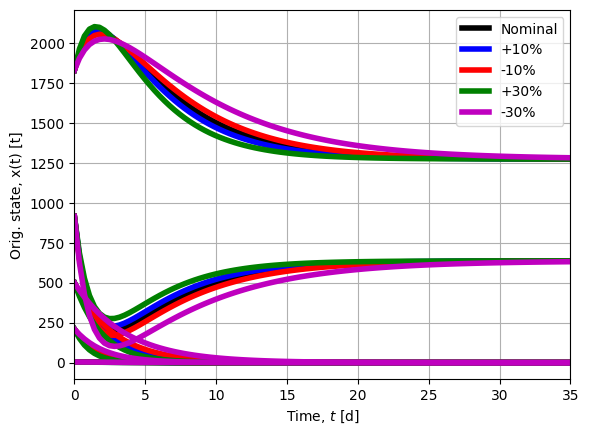

In [ ]:
# Recover and plot the original states, i.e., not translated (this is step (8)):
x_tilde = TimeResponseData.states
x_tilde_10p = TimeResponseData_10p.states
x_tilde_10m = TimeResponseData_10m.states
x_tilde_30p = TimeResponseData_30p.states
x_tilde_30m = TimeResponseData_30m.states

# Nominal states:
x1 = x_tilde[0] + x1e
x2 = x_tilde[1] + x2e
x3 = x_tilde[2] + x3e
x4 = x_tilde[3] + x4e
x7 = x_tilde[4] + x7e

# States with uncertainty:
x1_10p = x_tilde_10p[0] + x1e
x2_10p = x_tilde_10p[1] + x2e
x3_10p = x_tilde_10p[2] + x3e
x4_10p = x_tilde_10p[3] + x4e
x7_10p = x_tilde_10p[4] + x7e
#
x1_10m = x_tilde_10m[0] + x1e
x2_10m = x_tilde_10m[1] + x2e
x3_10m = x_tilde_10m[2] + x3e
x4_10m = x_tilde_10m[3] + x4e
x7_10m = x_tilde_10m[4] + x7e
#
x1_30p = x_tilde_30p[0] + x1e
x2_30p = x_tilde_30p[1] + x2e
x3_30p = x_tilde_30p[2] + x3e
x4_30p = x_tilde_30p[3] + x4e
x7_30p = x_tilde_30p[4] + x7e
#
x1_30m = x_tilde_30m[0] + x1e
x2_30m = x_tilde_30m[1] + x2e
x3_30m = x_tilde_30m[2] + x3e
x4_30m = x_tilde_30m[3] + x4e
x7_30m = x_tilde_30m[4] + x7e


# Plot of nominal and altered states:
plt.plot(TimeResponseData.time, x1, 'k', linewidth=4)
plt.plot(TimeResponseData.time, x2, 'k', linewidth=4, label='_nolegend_')
plt.plot(TimeResponseData.time, x3, 'k', linewidth=4, label='_nolegend_')
plt.plot(TimeResponseData.time, x4, 'k', linewidth=4, label='_nolegend_')
plt.plot(TimeResponseData.time, x7, 'k', linewidth=4, label='_nolegend_')
#
plt.plot(TimeResponseData_10p.time, x1_10p, 'b', linewidth=4)
plt.plot(TimeResponseData_10p.time, x2_10p, 'b', linewidth=4, label='_nolegend_')
plt.plot(TimeResponseData_10p.time, x3_10p, 'b', linewidth=4, label='_nolegend_')
plt.plot(TimeResponseData_10p.time, x4_10p, 'b', linewidth=4, label='_nolegend_')
plt.plot(TimeResponseData_10p.time, x7_10p, 'b', linewidth=4, label='_nolegend_')
#
plt.plot(TimeResponseData_10m.time, x1_10m, 'r', linewidth=4)
plt.plot(TimeResponseData_10m.time, x2_10m, 'r', linewidth=4, label='_nolegend_')
plt.plot(TimeResponseData_10m.time, x3_10m, 'r', linewidth=4, label='_nolegend_')
plt.plot(TimeResponseData_10m.time, x4_10m, 'r', linewidth=4, label='_nolegend_')
plt.plot(TimeResponseData_10m.time, x7_10m, 'r', linewidth=4, label='_nolegend_')
#
plt.plot(TimeResponseData_30p.time, x1_30p, 'g', linewidth=4)
plt.plot(TimeResponseData_30p.time, x2_30p, 'g', linewidth=4, label='_nolegend_')
plt.plot(TimeResponseData_30p.time, x3_30p, 'g', linewidth=4, label='_nolegend_')
plt.plot(TimeResponseData_30p.time, x4_30p, 'g', linewidth=4, label='_nolegend_')
plt.plot(TimeResponseData_30p.time, x7_30p, 'g', linewidth=4, label='_nolegend_')
#
plt.plot(TimeResponseData_30m.time, x1_30m, 'm', linewidth=4)
plt.plot(TimeResponseData_30m.time, x2_30m, 'm', linewidth=4, label='_nolegend_')
plt.plot(TimeResponseData_30m.time, x3_30m, 'm', linewidth=4, label='_nolegend_')
plt.plot(TimeResponseData_30m.time, x4_30m, 'm', linewidth=4, label='_nolegend_')
plt.plot(TimeResponseData_30m.time, x7_30m, 'm', linewidth=4, label='_nolegend_')

plt.xlabel(r'Time, $t$ [d]')
plt.ylabel('Orig. state, x(t) [t]')
plt.xlim(0, 35)
plt.xticks(np.arange(0, 36, step=5))
plt.yticks(np.arange(0, 2100, step=250))
plt.legend(['Nominal', '+10%','-10%','+30%','-30%'], loc='upper right')
plt.rcParams.update({'font.size': 30})
plt.grid()

print("x0 =", x0) # original initial conditions
print("xe =", xe)

/tmp/ipykernel_948/2205253381.py:30: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  u[i] = sample_u
/tmp/ipykernel_948/2205253381.py:47: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  u_10p[i] = sample_u_10p
/tmp/ipykernel_948/2205253381.py:63: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  u_10m[i] = sample_u_10m
/tmp/ipykernel_948/2205253381.py:79: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure yo

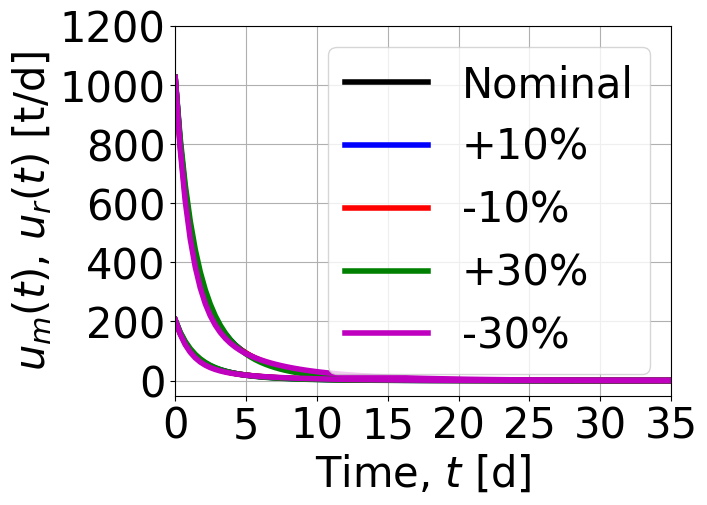

In [ ]:
# Plot u(t) = -K*(y - C*x_e) + v_e (this is step (9)):
u = -1000*np.ones(len(TimeResponseData.time))
u_10p = -1000*np.ones(len(TimeResponseData_10p.time))
u_10m = -1000*np.ones(len(TimeResponseData_10m.time))
u_30p = -1000*np.ones(len(TimeResponseData_30p.time))
u_30m = -1000*np.ones(len(TimeResponseData_30m.time))
mat1 = np.matmul(C, xe)

n_m = 5
n_r = 1

for i in range(len(TimeResponseData.time)):
  # the library returns y_tilde = C*x_tilde, so you need to calculate y = C*x:

  # Nominal system:
  x1_tilde_i = TimeResponseData.states[0,i]
  x2_tilde_i = TimeResponseData.states[1,i]
  x3_tilde_i = TimeResponseData.states[2,i]
  x4_tilde_i = TimeResponseData.states[3,i]
  x7_tilde_i = TimeResponseData.states[4,i]
  x_tilde_i = np.array([[x1_tilde_i],
                 [x2_tilde_i],
                 [x3_tilde_i],
                 [x4_tilde_i],
                 [x7_tilde_i]])
  yi = np.matmul(C, x_tilde_i + xe)
  mat2 = yi - mat1
  mat3 = np.matmul(K, mat2)
  sample_u = -mat3 + v_e
  u[i] = sample_u
  #  System with uncertainty:
  # +10%:
  x1_tilde_i_10p = TimeResponseData_10p.states[0,i]
  x2_tilde_i_10p = TimeResponseData_10p.states[1,i]
  x3_tilde_i_10p = TimeResponseData_10p.states[2,i]
  x4_tilde_i_10p = TimeResponseData_10p.states[3,i]
  x7_tilde_i_10p = TimeResponseData_10p.states[4,i]
  x_tilde_i_10p = np.array([[x1_tilde_i_10p],
                 [x2_tilde_i_10p],
                 [x3_tilde_i_10p],
                 [x4_tilde_i_10p],
                 [x7_tilde_i_10p]])
  yi_10p = np.matmul(C, x_tilde_i_10p + xe)
  mat2_10p = yi_10p - mat1
  mat3_10p = np.matmul(K, mat2_10p)
  sample_u_10p = -mat3_10p + v_e
  u_10p[i] = sample_u_10p
  # -10%:
  x1_tilde_i_10m = TimeResponseData_10m.states[0,i]
  x2_tilde_i_10m = TimeResponseData_10m.states[1,i]
  x3_tilde_i_10m = TimeResponseData_10m.states[2,i]
  x4_tilde_i_10m = TimeResponseData_10m.states[3,i]
  x7_tilde_i_10m = TimeResponseData_10m.states[4,i]
  x_tilde_i_10m = np.array([[x1_tilde_i_10m],
                 [x2_tilde_i_10m],
                 [x3_tilde_i_10m],
                 [x4_tilde_i_10m],
                 [x7_tilde_i_10m]])
  yi_10m = np.matmul(C, x_tilde_i_10m + xe)
  mat2_10m = yi_10m - mat1
  mat3_10m = np.matmul(K, mat2_10m)
  sample_u_10m = -mat3_10m + v_e
  u_10m[i] = sample_u_10m
  # +30%
  x1_tilde_i_30p = TimeResponseData_30p.states[0,i]
  x2_tilde_i_30p = TimeResponseData_30p.states[1,i]
  x3_tilde_i_30p = TimeResponseData_30p.states[2,i]
  x4_tilde_i_30p = TimeResponseData_30p.states[3,i]
  x7_tilde_i_30p = TimeResponseData_30p.states[4,i]
  x_tilde_i_30p = np.array([[x1_tilde_i_30p],
                 [x2_tilde_i_30p],
                 [x3_tilde_i_30p],
                 [x4_tilde_i_30p],
                 [x7_tilde_i_30p]])
  yi_30p = np.matmul(C, x_tilde_i_30p + xe)
  mat2_30p = yi_30p - mat1
  mat3_30p = np.matmul(K, mat2_30p)
  sample_u_30p = -mat3_30p + v_e
  u_30p[i] = sample_u_30p
  # -30%
  x1_tilde_i_30m = TimeResponseData_30m.states[0,i]
  x2_tilde_i_30m = TimeResponseData_30m.states[1,i]
  x3_tilde_i_30m = TimeResponseData_30m.states[2,i]
  x4_tilde_i_30m = TimeResponseData_30m.states[3,i]
  x7_tilde_i_30m = TimeResponseData_30m.states[4,i]
  x_tilde_i_30m = np.array([[x1_tilde_i_30m],
                 [x2_tilde_i_30m],
                 [x3_tilde_i_30m],
                 [x4_tilde_i_30m],
                 [x7_tilde_i_30m]])
  yi_30m = np.matmul(C, x_tilde_i_30m + xe)
  mat2_30m = yi_30m - mat1
  mat3_30m = np.matmul(K, mat2_30m)
  sample_u_30m = -mat3_30m + v_e
  u_30m[i] = sample_u_30m

# Split inputs:
u_m = (n_m/(n_m+n_r))*u
u_r = (n_r/(n_m+n_r))*u
#
u_m_10p = (n_m/(n_m+n_r))*u_10p
u_r_10p = (n_r/(n_m+n_r))*u_10p
#
u_m_10m = (n_m/(n_m+n_r))*u_10m
u_r_10m = (n_r/(n_m+n_r))*u_10m
#
u_m_30p = (n_m/(n_m+n_r))*u_30p
u_r_30p = (n_r/(n_m+n_r))*u_30p
#
u_m_30m = (n_m/(n_m+n_r))*u_30m
u_r_30m = (n_r/(n_m+n_r))*u_30m


# Plot of nominal and altered control inputs:
plt.plot(TimeResponseData.time, u_m, 'k', linewidth=4)
plt.plot(TimeResponseData.time, u_r, 'k', linewidth=4, label='_nolegend_')
#
plt.plot(TimeResponseData_10p.time, u_m_10p, 'b', linewidth=4)
plt.plot(TimeResponseData_10p.time, u_r_10p, 'b', linewidth=4, label='_nolegend_')
#
plt.plot(TimeResponseData_10m.time, u_m_10m, 'r', linewidth=4)
plt.plot(TimeResponseData_10m.time, u_r_10m, 'r', linewidth=4, label='_nolegend_')
#
plt.plot(TimeResponseData_30p.time, u_m_30p, 'g', linewidth=4)
plt.plot(TimeResponseData_30p.time, u_r_30p, 'g', linewidth=4, label='_nolegend_')
#
plt.plot(TimeResponseData_30m.time, u_m_30m, 'm', linewidth=4)
plt.plot(TimeResponseData_30m.time, u_r_30m, 'm', linewidth=4, label='_nolegend_')

plt.xlabel(r'Time, $t$ [d]')
plt.ylabel(r'$u_m(t)$, $u_r(t)$ [t/d]')
plt.xlim(0, 35)
plt.legend(['Nominal', '+10%','-10%', '+30%', '-30%'], loc='upper right')
plt.xticks(np.arange(0, 36, step=5))
plt.yticks(np.arange(0, 1300, step=200))
plt.rcParams.update({'font.size': 30})
plt.grid()